In [1]:
import json
import numpy as np
import reboundx as rbx
from matplotlib import pyplot as plt
from matplotlib.animation import FuncAnimation
import rebound as rb
from celmech.nbody_simulation_utilities import get_simarchive_integration_results
from pathlib import Path

# Edit these settings before running the notebook. Paths are relative to the
# notebook kernel's working directory unless you supply an absolute path.
OUTPUT_ROOT = Path("migration_outputs").resolve()
RUN_NAME = "migration_example1"
REQUESTED_DURATION_SECONDS = 15.0
FPS = 30
CONTROL_SAMPLES = 4096
FREQUENCY_MULTIPLIER = 20.0   # orbital frequency (1/yr) -> audible Hz
ECCENTRICITY_MULTIPLIER = 30.0
AUDIO_SAMPLE_RATE = 48000
FADE_IN_SECONDS = 0.1
FADE_OUT_SECONDS = 1.0
TOTAL_AMPLITUDE = 0.3

assert REQUESTED_DURATION_SECONDS > 0 and FPS > 0
N_FRAMES = max(2, round(REQUESTED_DURATION_SECONDS * FPS))
DURATION_SECONDS = N_FRAMES / FPS  # actual encoded video duration
RUN_DIR = OUTPUT_ROOT / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
ARCHIVE_PATH = RUN_DIR / f"{RUN_NAME}.sa"
ANIMATION_PATH = RUN_DIR / f"{RUN_NAME}.mp4"
CONFIG_PATH = RUN_DIR / "sonification.json"
print(f"Output: {RUN_DIR}\nDuration: {DURATION_SECONDS:g} s ({N_FRAMES} frames)")

Output: /Users/hadden/Projects/SimulationSonification/migration_outputs/migration_example1
Duration: 15 s (450 frames)


In [2]:
sim = rb.Simulation()
sim.units = ('yr', 'AU', 'Msun')
sim.add(m=1)
sim.add(m=1e-5,a=0.2)
sim.add(m=1e-5,a=0.4)
sim.add(m=1e-5,a=0.6)
sim.move_to_com()
extras = rbx.Extras(sim)
mig = extras.load_force("type_I_migration")

extras.add_force(mig)
mig.params["tIm_scale_height_1"] = 0.03
mig.params["tIm_surface_density_1"] = 1.1e-4/4 # 1000 g/cm^2 surface density in Msun/AU^2
mig.params["tIm_surface_density_exponent"] = 1
mig.params["tIm_flaring_index"] = 0.25

mig.params["ide_position"] = 0.1
mig.params["ide_width"] = mig.params["tIm_scale_height_1"]*mig.params["ide_position"]**mig.params["tIm_flaring_index"]
print('Planet will stop within {0:.3f} AU of the inner disk edge at {1} AU'.format(mig.params["ide_width"], mig.params["ide_position"]))


Planet will stop within 0.017 AU of the inner disk edge at 0.1 AU


In [3]:
sim.integrator = 'whfast'
sim.dt = mig.params["ide_position"]**(3/2)/20
sim.save_to_file(str(ARCHIVE_PATH),interval = 20,delete_file=True)
sim.integrate(9e4)

/Users/hadden/miniconda3/envs/celmech/lib/python3.13/site-packages/rebound/simulation.py:259: RuntimeWarning: REBOUNDx: Passing a velocity-dependent force to WHFAST. Need to apply as an operator. See REBOUNDx paper sec 5.1.
  warnings.warn(msg[1:], RuntimeWarning)


In [4]:
results = get_simarchive_integration_results(str(ARCHIVE_PATH))

/Users/hadden/miniconda3/envs/celmech/lib/python3.13/site-packages/rebound/simulationarchive.py:150: RuntimeWarning: You have to reset function pointers after creating a reb_simulation struct with a binary file.
  warnings.warn(message, RuntimeWarning)


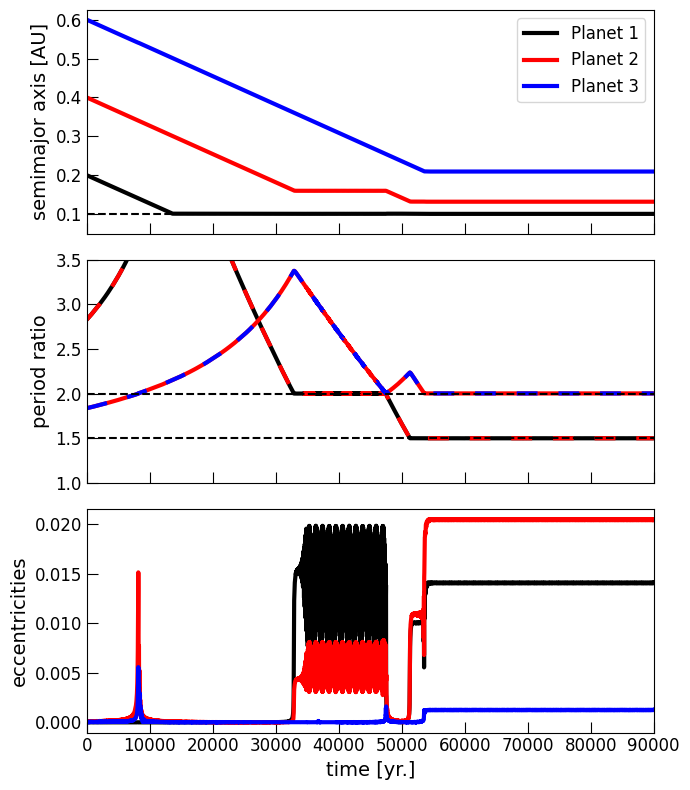

In [5]:
time = np.asarray(results["time"], dtype=float)
a_data = np.asarray(results["a"], dtype=float)
p_data = np.asarray(results["P"], dtype=float)
e_data = np.asarray(results["e"], dtype=float)
N_PLANETS = p_data.shape[0]
if (time.ndim != 1 or len(time) < 2 or not np.all(np.diff(time) > 0)
        or not np.isfinite(time).all()):
    raise ValueError("Simulation times must be finite and strictly increasing.")
if N_PLANETS < 1:
    raise ValueError("At least one planet is required.")
for name, values in [("a", a_data), ("P", p_data), ("e", e_data)]:
    if values.shape != (N_PLANETS, len(time)) or not np.isfinite(values).all():
        raise ValueError(f"Invalid {name} array: expected (planets, times).")
if np.any(p_data <= 0) or np.any(e_data < 0):
    raise ValueError("Periods must be positive and eccentricities nonnegative.")
colors = ["k", "r", "b"] + list(plt.get_cmap("tab20").colors)
colors = [colors[i % len(colors)] for i in range(N_PLANETS)]
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(7, 8))
lines, series = [], []
for i in range(N_PLANETS):
    line, = ax[0].plot(time, a_data[i], color=colors[i], lw=3,
                       label=f"Planet {i + 1}")
    lines.append(line); series.append(a_data[i])
ax[0].legend(loc="best", fontsize=12)
ax[0].set_ylim(bottom=0.05)
ax[0].axhline(0.1, color="k", ls="--")
for i in range(N_PLANETS - 1):
    ratio = p_data[i + 1] / p_data[i]
    base, = ax[1].plot(time, ratio, color=colors[i], lw=3)
    dashed, = ax[1].plot(time, ratio, color=colors[i + 1], lw=3,
                         linestyle=(0, (5, 5)), dash_capstyle="butt")
    lines.extend([base, dashed]); series.extend([ratio, ratio])
ax[1].set_ylim(1, 3.5)
for resonance in [1.5, 2]:
    ax[1].axhline(resonance, color="k", ls="--")
for i in range(N_PLANETS):
    line, = ax[2].plot(time, e_data[i], color=colors[i], lw=3)
    lines.append(line); series.append(e_data[i])
ax[2].set_xlim(time[0], time[-1])
for axis in ax:
    axis.tick_params(direction="in", labelsize=12, size=8)
    axis.tick_params(direction="in", which="minor", size=6)
    axis.set_autoscale_on(False)
for axis, label in zip(ax, ["semimajor axis [AU]", "period ratio", "eccentricities"]):
    axis.set_ylabel(label, fontsize=14)
ax[2].set_xlabel("time [yr.]", fontsize=14)
fig.tight_layout()

In [6]:
# Frame k shows the state at the beginning of its video frame interval.
# Audio uses the same linear simulation-time -> playback-time mapping.
frame_times = time[0] + (time[-1] - time[0]) * np.arange(N_FRAMES) / N_FRAMES

def init():
    for line in lines:
        line.set_data([], [])
    return lines

def update(current_time):
    stop = np.searchsorted(time, current_time, side="right")
    for line, values in zip(lines, series):
        # Include an interpolated endpoint, even with sparse simulation output.
        x = np.append(time[:stop], current_time)
        y = np.append(values[:stop], np.interp(current_time, time, values))
        line.set_data(x, y)
    return lines

ani = FuncAnimation(fig, update, frames=frame_times, init_func=init,
                    interval=1000 / FPS, blit=True, repeat=False)
plt.show()

In [7]:
# Requires FFmpeg. This file has exactly N_FRAMES / FPS seconds.
ani.save(str(ANIMATION_PATH), writer="ffmpeg", fps=FPS, dpi=150)
print(ANIMATION_PATH)

/Users/hadden/Projects/SimulationSonification/migration_outputs/migration_example1/migration_example1.mp4


In [8]:
# Uniform-time samples avoid treating irregular archive times as uniform.
if CONTROL_SAMPLES < 2:
    raise ValueError("CONTROL_SAMPLES must be at least 2.")
if (FREQUENCY_MULTIPLIER <= 0 or ECCENTRICITY_MULTIPLIER < 0
        or AUDIO_SAMPLE_RATE <= 0 or TOTAL_AMPLITUDE < 0
        or min(FADE_IN_SECONDS, FADE_OUT_SECONDS) < 0
        or FADE_IN_SECONDS + FADE_OUT_SECONDS > DURATION_SECONDS):
    raise ValueError("Invalid sonification settings or fades exceed duration.")
control_time = np.linspace(time[0], time[-1], CONTROL_SAMPLES)
n_data = np.column_stack([np.interp(control_time, time, 1 / p) for p in p_data])
e_export = np.column_stack([np.interp(control_time, time, e) for e in e_data])
frequency_csv = RUN_DIR / "orbital_frequency.csv"
eccentricity_csv = RUN_DIR / "eccentricity.csv"
np.savetxt(frequency_csv, n_data, delimiter=",")
np.savetxt(eccentricity_csv, e_export, delimiter=",")

config = {
    "schema_version": 1,
    "run_name": RUN_NAME,
    "n_planets": N_PLANETS,
    "n_samples": CONTROL_SAMPLES,
    "simulation_time_start_years": float(time[0]),
    "simulation_time_end_years": float(time[-1]),
    "duration_seconds": DURATION_SECONDS,
    "fps": FPS,
    "n_frames": N_FRAMES,
    # Relative to this JSON file so the complete run folder can be moved.
    "frequency_csv": frequency_csv.name,
    "eccentricity_csv": eccentricity_csv.name,
    "animation_file": ANIMATION_PATH.name,
    "recording_file": f"{RUN_NAME}.wav",
    "frequency_multiplier": FREQUENCY_MULTIPLIER,
    "eccentricity_multiplier": ECCENTRICITY_MULTIPLIER,
    "audio_sample_rate": AUDIO_SAMPLE_RATE,
    "fade_in_seconds": FADE_IN_SECONDS,
    "fade_out_seconds": FADE_OUT_SECONDS,
    "total_amplitude": TOTAL_AMPLITUDE,
    "wavetable_samples": 128,
    "wavetable_count": 20,
}
CONFIG_PATH.write_text(json.dumps(config, indent=2, allow_nan=False) + "\n")
print(f"SuperCollider configuration: {CONFIG_PATH}")

SuperCollider configuration: /Users/hadden/Projects/SimulationSonification/migration_outputs/migration_example1/sonification.json


Run the notebook from top to bottom. Keep `three_planet_chain.scd` and `rv_buffer_fill.scd` together. In SuperCollider, evaluate the script and select the printed `sonification.json` file. It renders the WAV offline, with the fade-out included in the video duration. The WAV and MP4 can then be combined with FFmpeg (see README).